In [178]:
import pandas as pd
import json
import matplotlib.pyplot as plt


In [188]:
dfs = []
for mode in ['none','conservative','adaptive','aggressive','dynamic','static']:
    with open('metrics_'+mode+'.json','r') as f:
        jsondata = json.load(f)
        df=pd.DataFrame.from_dict(jsondata['hourly_metrics'])
        df['mode']=mode
        df['hr']=(df['day']-1)*24+df['hour']
        dfs.append(df)

In [189]:
maindf = pd.concat(dfs)
maindf

,day,hour,total_bikes,avg_bikes_per_station,imbalance,trips_completed,redirected_trips,total_incentives,shortage_events,docking_shortage_events,avg_demand,avg_incentive,avg_trip_price,avg_trip_distance,mode,hr
0,1,0,319,6.38,1.214743,0,0,0.0,0,0,0.00,0.000000,0.000000,0.000000,none,0
1,1,1,319,6.38,1.309809,4,0,0.0,0,0,0.08,0.000000,2.976863,9.768630,none,1
2,1,2,319,6.38,2.028694,28,0,0.0,0,0,0.56,0.000000,2.987283,9.872828,none,2
3,1,3,319,6.14,3.181258,65,0,0.0,6,0,2.30,0.000000,3.074562,10.745617,none,3
4,1,4,319,5.86,3.616684,98,0,0.0,18,0,6.50,0.000000,3.029966,10.299660,none,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
115,5,19,332,6.10,2.744085,285,37,140.6,48,0,55.58,0.493333,3.018129,10.132431,static,115
116,5,20,332,6.16,2.618091,272,38,152.0,46,0,40.76,0.558824,3.017555,10.179236,static,116
117,5,21,332,6.00,2.952965,235,31,130.2,38,0,25.36,0.554043,3.026559,10.066407,static,117
118,5,22,332,5.76,3.332026,141,20,88.0,24,0,12.68,0.624113,3.002041,10.055597,static,118


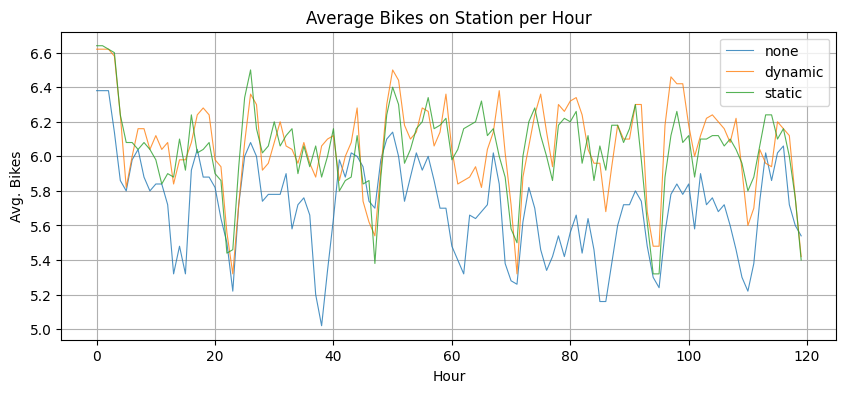

In [190]:
fig, ax = plt.subplots(1,1, figsize=(10,4))
for mode in ['none','dynamic','static']:
    data = maindf[maindf['mode']==mode]
    ax.plot(data['hr'], data['avg_bikes_per_station'], alpha=0.8, lw=0.8, label=mode)
    
ax.set_ylabel('Avg. Bikes')
ax.set_xlabel('Hour')
ax.legend()
ax.grid()
ax.set_title('Average Bikes on Station per Hour')
plt.show()

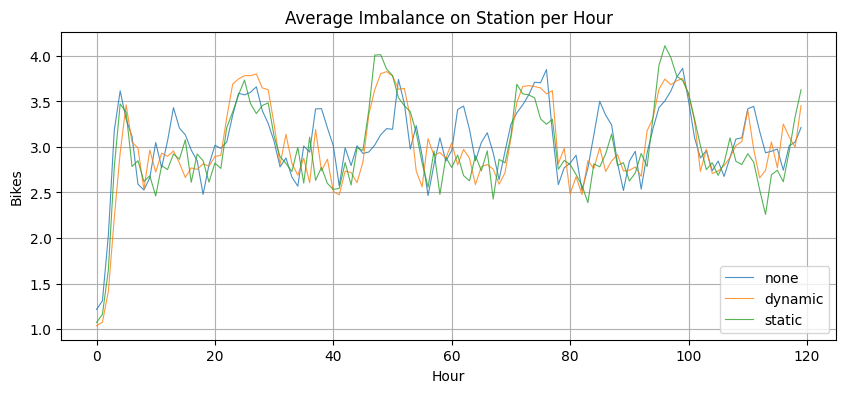

In [191]:
fig, ax = plt.subplots(1,1, figsize=(10,4))
for mode in ['none','dynamic','static']:
    data = maindf[maindf['mode']==mode]
    ax.plot(data['hr'], data['imbalance'], alpha=0.8, lw=0.8, label=mode)
    
ax.set_ylabel('Bikes')
ax.set_xlabel('Hour')
ax.legend()
ax.grid()
ax.set_title('Average Imbalance on Station per Hour')
plt.show()

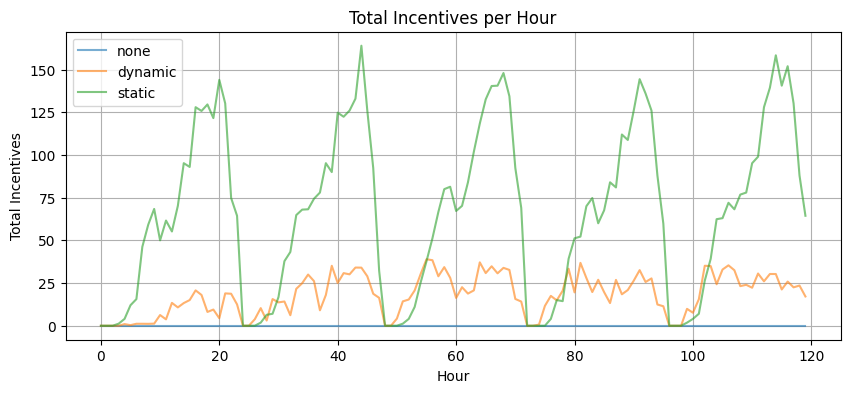

In [192]:
fig, ax = plt.subplots(1,1, figsize=(10,4))
for mode in ['none','dynamic','static']:
    data = maindf[maindf['mode']==mode]
    ax.plot(data['hr'], data['total_incentives'], alpha=0.6, label=mode)
    
ax.set_ylabel('Total Incentives')
ax.set_xlabel('Hour')
ax.legend()
ax.grid()

ax.set_title('Total Incentives per Hour')
plt.show()

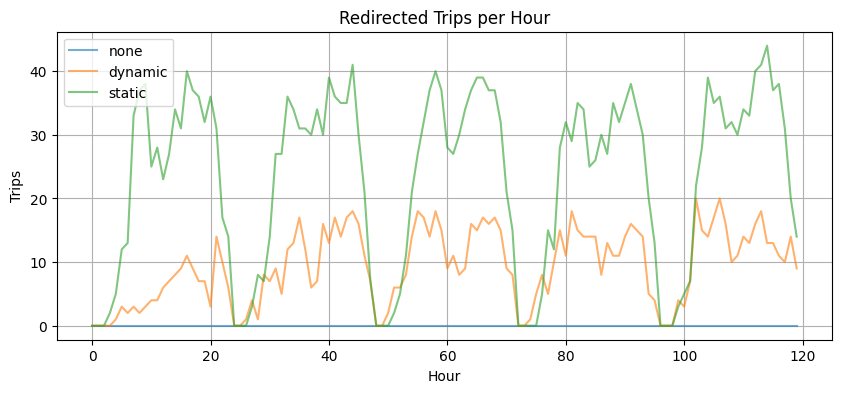

In [193]:
fig, ax = plt.subplots(1,1, figsize=(10,4))
for mode in ['none','dynamic','static']:
    data = maindf[maindf['mode']==mode]
    ax.plot(data['hr'], data['redirected_trips'], alpha=0.6, label=mode)
    
ax.set_ylabel('Trips')
ax.set_xlabel('Hour')
ax.legend()
ax.set_title('Redirected Trips per Hour')
ax.grid()

plt.show()

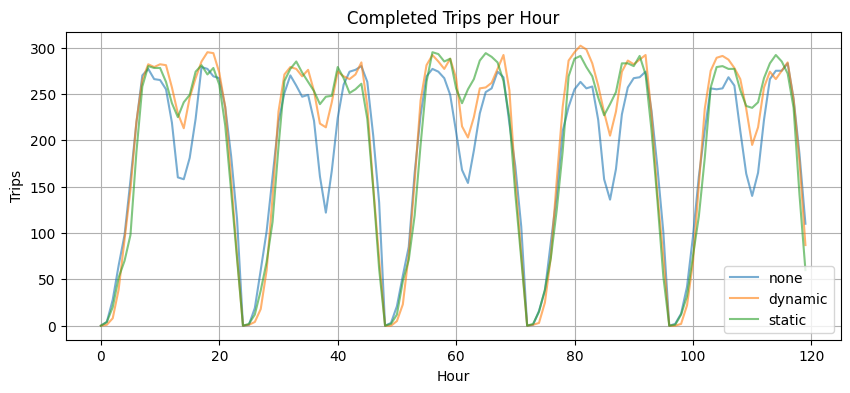

In [194]:
fig, ax = plt.subplots(1,1, figsize=(10,4))
for mode in ['none','dynamic','static']:
    data = maindf[maindf['mode']==mode]
    ax.plot(data['hr'], data['trips_completed'], alpha=0.6, label=mode)
    
ax.set_ylabel('Trips')
ax.set_xlabel('Hour')
ax.legend()
ax.grid()

ax.set_title('Completed Trips per Hour')
plt.show()

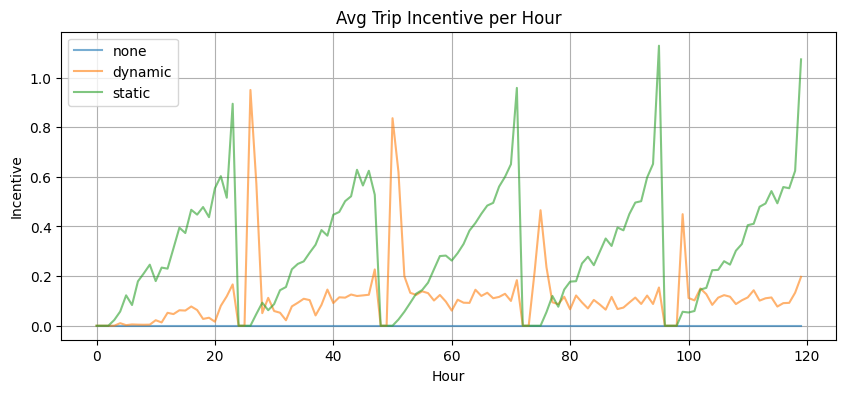

In [195]:
fig, ax = plt.subplots(1,1, figsize=(10,4))
for mode in ['none','dynamic','static']:
    data = maindf[maindf['mode']==mode]
    ax.plot(data['hr'], data['avg_incentive'], alpha=0.6, label=mode)
ax.set_ylabel('Incentive')
ax.set_xlabel('Hour')
ax.legend()
ax.grid()

ax.set_title('Avg Trip Incentive per Hour')
plt.show()

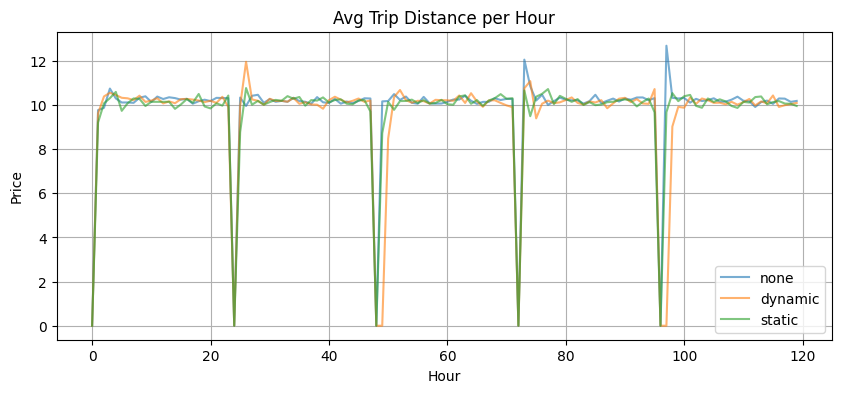

In [198]:
fig, ax = plt.subplots(1,1, figsize=(10,4))
for mode in ['none','dynamic','static']:
    data = maindf[maindf['mode']==mode]
    ax.plot(data['hr'], data['avg_trip_distance'], alpha=0.6, label=mode)
ax.set_ylabel('Price')
ax.set_xlabel('Hour')
ax.legend()
ax.grid()

ax.set_title('Avg Trip Distance per Hour')
plt.show()

<Axes: title={'center': 'redirected_trips'}, xlabel='mode'>

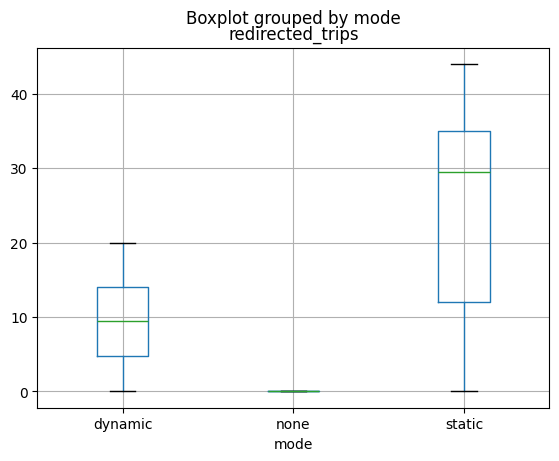

In [199]:
grouped = maindf[maindf['mode'].isin(['none','dynamic','static'])]
grouped.boxplot(column='redirected_trips', by='mode')


<Axes: title={'center': 'avg_bikes_per_station'}, xlabel='mode'>

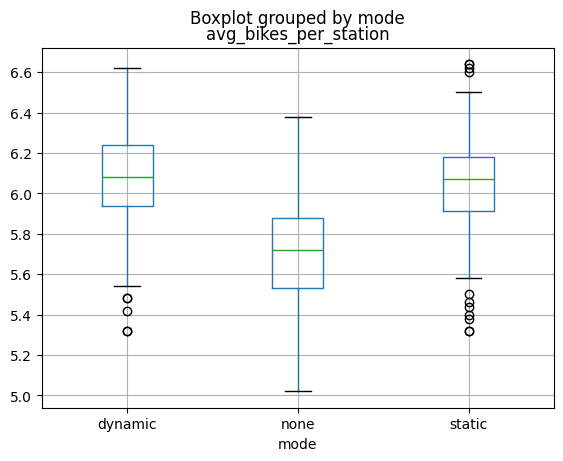

In [201]:
grouped = maindf[maindf['mode'].isin(['none','dynamic','static'])]
grouped.boxplot(column='avg_bikes_per_station', by='mode')

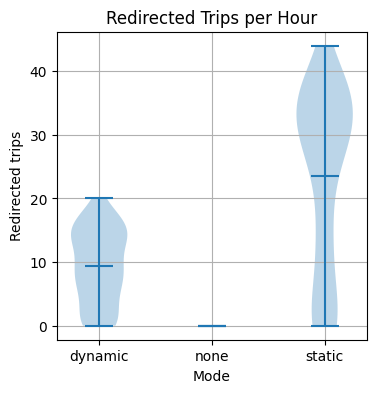

In [200]:
grouped = maindf[maindf['mode'].isin(['none','dynamic','static'])]
grouped = grouped.groupby(['mode'])['redirected_trips']
ds = [group.values for name, group in grouped]
fig, ax = plt.subplots(1,1, figsize=(4,4))

# Create the plot
ax.violinplot(dataset=ds, showmeans=True)
ax.set_xticks([y + 1 for y in range(len(ds))],
                  labels=grouped.groups.keys())
ax.set_ylabel('Redirected trips')
ax.set_xlabel('Mode')
ax.grid()
ax.set_title('Redirected Trips per Hour')
plt.show()

# static incentive gives us more redirections per hour

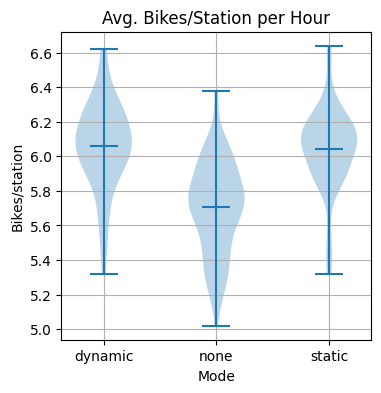

In [202]:
grouped = maindf[maindf['mode'].isin(['none','dynamic','static'])]
grouped = grouped.groupby(['mode'])['avg_bikes_per_station']
ds = [group.values for name, group in grouped]
fig, ax = plt.subplots(1,1, figsize=(4,4))

# Create the plot
ax.violinplot(dataset=ds, showmeans=True)
ax.set_xticks([y + 1 for y in range(len(ds))],
                  labels=grouped.groups.keys())
ax.set_ylabel('Bikes/station')
ax.set_xlabel('Mode')
ax.grid()
ax.set_title('Avg. Bikes/Station per Hour')
plt.show()

# static and dynamic incentive have similar avg but dynamic maintains a better bike capacity over a longer timespan

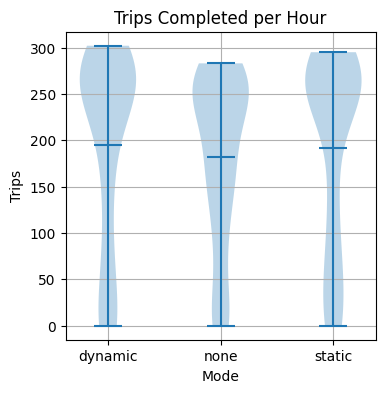

In [203]:
grouped = maindf[maindf['mode'].isin(['none','dynamic','static'])]
grouped = grouped.groupby(['mode'])['trips_completed']
ds = [group.values for name, group in grouped]
fig, ax = plt.subplots(1,1, figsize=(4,4))

# Create the plot
ax.violinplot(dataset=ds, showmeans=True)
ax.set_xticks([y + 1 for y in range(len(ds))],
                  labels=grouped.groups.keys())
ax.set_ylabel('Trips')
ax.set_xlabel('Mode')
ax.grid()
ax.set_title('Trips Completed per Hour')
plt.show()

# static and dynamic more trips completed compared to no incentive

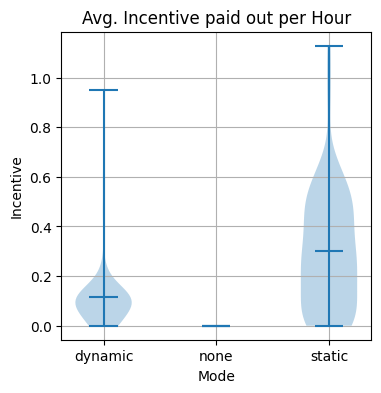

In [204]:
grouped = maindf[maindf['mode'].isin(['none','dynamic','static'])]
grouped = grouped.groupby(['mode'])['avg_incentive']
ds = [group.values for name, group in grouped]
fig, ax = plt.subplots(1,1, figsize=(4,4))

# Create the plot
ax.violinplot(dataset=ds, showmeans=True)
ax.set_xticks([y + 1 for y in range(len(ds))],
                  labels=grouped.groups.keys())
ax.set_ylabel('Incentive')
ax.set_xlabel('Mode')
ax.grid()
ax.set_title('Avg. Incentive paid out per Hour')
plt.show()

# static incentive costs more

In [205]:
dfsi = []
for mode in ['none','conservative','adaptive','aggressive','dynamic','static']:
    with open('incentive_analysis_'+mode+'.json','r') as f:
        jsondata = json.load(f)
        df=pd.DataFrame.from_dict(jsondata['daily_metrics'])
        df['mode']=mode
        #df['hr']=(df['day']-1)*24+df['hour']
        dfsi.append(df)

In [206]:
maindfi = pd.concat(dfsi)
maindfi

,day,total_trips,redirected_trips,redirect_rate,total_revenue,total_incentives,avg_incentive,bike_shortages,bike_docking_shortages,mode
0,1,5000,0,0.000000,15108.157793,0.000000,0.000000,830,0,none
1,2,5015,0,0.000000,15130.826986,0.000000,0.000000,1668,0,none
2,3,4953,0,0.000000,14944.194855,0.000000,0.000000,2505,0,none
3,4,4742,0,0.000000,14324.873647,0.000000,0.000000,3355,0,none
4,5,4951,0,0.000000,14935.379958,0.000000,0.000000,4194,0,none
0,1,5132,524,0.102104,15503.638155,508.611132,0.970632,826,0,conservative
1,2,5133,581,0.113189,15475.283677,596.338008,1.026399,1671,0,conservative
2,3,5111,601,0.117590,15417.585021,583.634471,0.971106,2519,0,conservative
3,4,5113,565,0.110503,15428.061789,568.358376,1.005944,3357,0,conservative
4,5,5126,554,0.108076,15459.991721,562.613021,1.015547,4200,0,conservative


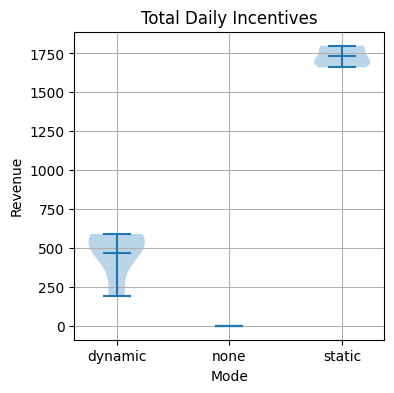

In [209]:
grouped = maindfi[maindfi['mode'].isin(['none','dynamic','static'])]
grouped = grouped.groupby(['mode'])['total_incentives']
ds = [group.values for name, group in grouped]
fig, ax = plt.subplots(1,1, figsize=(4,4))

# Create the plot
ax.violinplot(dataset=ds, showmeans=True)
ax.set_xticks([y + 1 for y in range(len(ds))],
                  labels=grouped.groups.keys())
ax.set_ylabel('Revenue')
ax.set_xlabel('Mode')
ax.grid()
ax.set_title('Total Daily Incentives')
plt.show()

# static incentive costs more

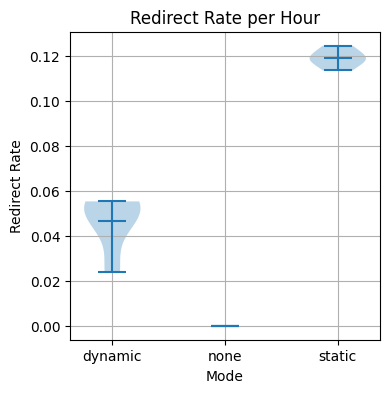

In [212]:
grouped = maindfi[maindfi['mode'].isin(['none','dynamic','static'])]
grouped = grouped.groupby(['mode'])['redirect_rate']
ds = [group.values for name, group in grouped]
fig, ax = plt.subplots(1,1, figsize=(4,4))

# Create the plot
ax.violinplot(dataset=ds, showmeans=True)
ax.set_xticks([y + 1 for y in range(len(ds))],
                  labels=grouped.groups.keys())
ax.set_ylabel('Redirect Rate')
ax.set_xlabel('Mode')
ax.grid()
ax.set_title('Redirect Rate per Hour')
plt.show()

# static incentive results in more redirects

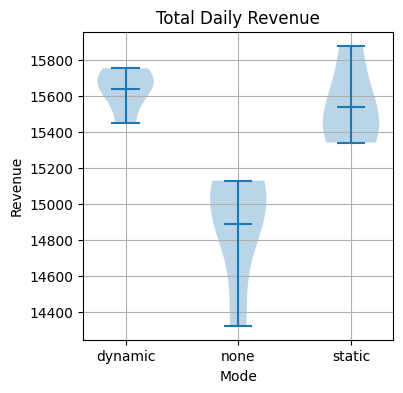

In [208]:
grouped = maindfi[maindfi['mode'].isin(['none','dynamic','static'])]
grouped = grouped.groupby(['mode'])['total_revenue']
ds = [group.values for name, group in grouped]
fig, ax = plt.subplots(1,1, figsize=(4,4))

# Create the plot
ax.violinplot(dataset=ds, showmeans=True)
ax.set_xticks([y + 1 for y in range(len(ds))],
                  labels=grouped.groups.keys())
ax.set_ylabel('Revenue')
ax.set_xlabel('Mode')
ax.grid()
ax.set_title('Total Daily Revenue')
plt.show()

# static and dynamic result in more revenue than no incentive, probably due to more completed trips

/var/folders/cq/dpv74_vx6z763s2ht4_54zx1tyht7_/T/ipykernel_23169/2825599481.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  grouped['net_profit'] = grouped['total_revenue']-grouped['total_incentives']


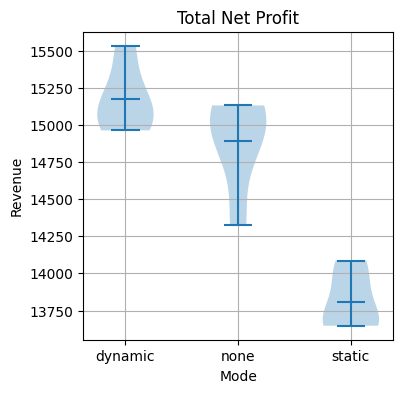

In [211]:
grouped = maindfi[maindfi['mode'].isin(['none','dynamic','static'])]
grouped['net_profit'] = grouped['total_revenue']-grouped['total_incentives']
grouped = grouped.groupby(['mode'])['net_profit']
ds = [group.values for name, group in grouped]
fig, ax = plt.subplots(1,1, figsize=(4,4))

# Create the plot
ax.violinplot(dataset=ds, showmeans=True)
ax.set_xticks([y + 1 for y in range(len(ds))],
                  labels=grouped.groups.keys())
ax.set_ylabel('Revenue')
ax.set_xlabel('Mode')
ax.grid()
ax.set_title('Total Net Profit')
plt.show()

# dynamic results in more net profit due to more completed trips and less incentive payout